# **FITs File in action: CRUD, Multi-Extention, `n`D-Cube**
**Project:** Astronomical Image Data Matrix Compilation  
**Objective:** Porting legacy **C CFITSIO** linear ramp operations to optimized **Python** code.

This notebook establishes an automated pipeline to construct **`.fits`** file types, assign appropriate headers, and visually verify dataset arrays.

**FITS** is a standard format for exchanging astronomical data. A file in **FITS** format consists of a series of **Header Data Units** (**HDUs**), each containing two components: an **ASCII** text header and the binary data. The header contains a series of keywords that describe the data in a particular **HDU** and the data component may immediately follow the header. [A Primer on the FITS Data Format](https://fits.gsfc.nasa.gov/fits_primer.html)

* The long-string convention allows **FITS** headers to specify string values longer than **68** characters.
* The **FITS** hierarchical grouping convention defines a kind of **FITS** table which describes an association of **HDUs** which may span multiple files.
* The header inheritance convention allows for **FITS** header information in the primary **HDU** to be used to default information in subsequent **HDUs**.
* The **HIERARCH** keyword convention allows **FITS** keywords to be longer than the standard value of **8** characters.

This data dictionary lists the **53 keywords** currently defined in the [FITS Standard](https://heasarc.gsfc.nasa.gov/docs/fcg/standard_dict.html)

```
(blank)  CROTAn   EQUINOX  NAXISn   TBCOLn   TUNITn
AUTHOR   CRPIXn   EXTEND   OBJECT   TDIMn    TZEROn
BITPIX   CRVALn   EXTLEVEL OBSERVER TDISPn   XTENSION
BLANK    CTYPEn   EXTNAME  ORIGIN   TELESCOP
BLOCKED  DATAMAX  EXTVER   PCOUNT   TFIELDS
BSCALE   DATAMIN  GCOUNT   PSCALn   TFORMn
BUNIT    DATE     GROUPS   PTYPEn   THEAP
BZERO    DATE-OBS HISTORY  PZEROn   TNULLn
CDELTn   END      INSTRUME REFERENC TSCALn
COMMENT  EPOCH    NAXIS    SIMPLE   TTYPEn
```

*Many **FITS** readers can read information that has been stored using standard compression algorithms, particularly the **`.Z`** and **`.gz`*** files created by the **Unix** **compress** and **gzip** utilities. **FITS** also supports compression internally for both images and binary tables which can be more efficient for astronomical data and can also allows access to uncompressed image metadata.

##### 25 Oct 2026 by Oleg G.Kapranov

## **Create FITs Image** `300x200`

with 1 image extension and save it to disk to filled gradient as data.

### Step 1: Initialize Project Environment
Ensure your system has the proper astronomy computing environments installed.

In [ ]:
!pip install astropy numpy matplotlib pandas

### Step 2: Import Core Modules & Configuration
Define explicit pixel matrices matching your core data dimensions ($300 \times 200$ array dimensions).

In [ ]:
import astropy.io.fits as fits
import matplotlib.pyplot as plt
import numpy as np

# Set the original structural parameters
width = 300
height = 200

### Step 3: Array Initialization & Matrix Generation
Vectorized representation of the original programmatic ramp function `array[jj][ii] = ii + jj` using NumPy index spaces.

In [ ]:
# Construct index arrays for structural height and width dimensions
jj, ii = np.indices((height, width))
data_array = (ii + jj).astype(np.int16)  # Replicates SHORT_IMG pixel structure

print(f"Data array constructed successfully with matrix shape: {data_array.shape}")

### Step 4: Construct FITS HDU & File Output
Wrap raw arrays into Primary Header Data Units (HDUs) and commit metadata headers to disk storage.

In [ ]:
# Instantiate primary header data unit wrapper
hdu = fits.PrimaryHDU(data=data_array)

# Insert explicit science metrics tracking metadata keys
hdu.header["EXPOSURE"] = (1500, "Total Exposure Time")

# --- Injecting the Section Block with Empty Lines ------------------------------------------
hdu.header.append(('COMMENT', ''))                                   # <--- Empty line before
hdu.header.append(('COMMENT', '          Programm information '))    # <--- Section title
hdu.header.append(('COMMENT', ''))                                   # <--- Empty line after
# ----------------------------------------------------------------
# --- Instead of using tuples in `.append()`, can also use native methods -------------------
hdu.header.add_comment('')                                           # <--- Break line
hdu.header.add_comment('               Photometry ')                 # <--- Title line
hdu.header.add_comment('')                                           # <--- Break line
# -------------------------------------------------------------------------------------------
hdu.header.append((' ', ''))                                         # <--- Empty line before
hdu.header.append((' ', '        Calibration step information '))    # <--- Section title
hdu.header.append((' ', ''))                                         # <--- Empty line after

# Dynamically compute and inject CHECKSUM and DATASUM keys
hdu.add_checksum()

# Serialize the complete entity matrix payload to a persistent file structure
output_filename = "demo_image.fits"
hdu.writeto(output_filename, overwrite=True)

print(f"Target FITS structure written successfully to disk location: {output_filename}")

In [ ]:
!ls demo_image.fits

### Step 5: Readback & Quality Assurance Plotting
Re-open files from storage to read back parameters and visualize arrays.

In [ ]:
# Open the freshly minted asset interface
with fits.open("demo_image.fits") as hdul:
    print("--- COMPILED FITS METADATA DATASET ---\n")
    print(repr(hdul[0].header))
    
    # Visual confirmation plot mapping matrices
    plt.figure(figsize=(10, 6))
    plt.imshow(hdul[0].data, cmap="inferno", origin="lower")
    plt.colorbar(label="Data Value Gradient Vector")
    plt.title("FITS Output Verification Canvas (Linear Ramp Structure)")
    plt.xlabel("NAXIS1 Axis Matrix Element Range (Width)")
    plt.ylabel("NAXIS2 Axis Matrix Element Range (Height)")
    plt.show()

## **Create FITs Image Pixel** `20x20`

with 1 image extension and save it to disk to pixel as data.

In [ ]:
import astropy.io.fits as fits
import numpy as np
import datetime

# Get the current timezone-aware UTC time
utc_now = datetime.datetime.now(datetime.UTC)

# Format it into a standard FITS date string (e.g., '2026-10-28')
fits_date_short = utc_now.strftime('%Y-%m-%d')

# Format it into a standard FITS date string (e.g., '2026-10-28T14:16:30')
fits_date_string = utc_now.strftime('%Y-%m-%dT%H:%M:%S')

# 1d array
x=np.linspace(-100,100,400)

# 1d data
y=np.sin(x)

# convert y into 2d array as image data
img=np.reshape(y,(20,20))

# add header information
hdr = fits.Header()
hdr['Telscope']='Explore Scientific ED127 APO Refractor.'
hdr['OPTICAL']='Air-spaced triplet apochromat'
hdr['APERTURE']='127 mm (5 inches)'
hdr['FOCALEN']='952 mm'
hdr['FOCALRAT']='f/7.5'
hdr['GLASSTYP']='Hoya ED glass FCD1 on standard lines'
hdr['DATE'] = (fits_date_short, 'File creation date (UTC)')
hdr['DATE-OBS'] = (fits_date_string, 'Date/Time of file creation timestamp')
hdr.append(('EXPTIME', 300.0, 'Exposure time in seconds'))
hdr.add_history('Data reduced on 2026-10-28')
hdr.append(('', '===================================================================='))
hdr.append(('', '                   --- PIPELINE METADATA ---'))
hdr.append(('', '===================================================================='))
hdr['COMMENT']='In late 2012, Explore Scientific updated the design of the ED127'
hdr['COMMENT']='telescope to improve usability and accommodate astrophotographers.'
hdr['COMMENT']='Prior models featured a completely detachable dew shield that had'
hdr['COMMENT']='to be physically unthreaded or pulled off, reversed, and slid back'
hdr['COMMENT']='over the optical tube assembly (OTA) to fit into its storage case.'
hdr['COMMENT']='The version rolling out at the end of 2012 replaced this with an'
hdr['COMMENT']='integrated sliding dew shield. This allows users to smoothly shift'
hdr['COMMENT']='the dew shield back and forth directly on the tube without removing'
hdr['COMMENT']='it. The upgrade was not just limited to the dew shield; Explore'
hdr['COMMENT']='Scientific also upgraded the mechanical backend to a beefier dual-'
hdr['COMMENT']='speed focuser. The Original Version: Came equipped with a 2-inch'
hdr['COMMENT']='dual-speed Crayford-style focuser. While smooth for visual tracking,'
hdr['COMMENT']='Crayford designs can occasionally slip or experience a minor image'
hdr['COMMENT']='shift when locked or when bearing heavy camera payloads.'
hdr['COMMENT']='The Essential and Later Editions: Transitioned over to robust,'
hdr['COMMENT']='heavy-duty Rack-and-Pinion mechanisms (such as the Hexafoc and'
hdr['COMMENT']='2.5-inch R&P systems). These gears are specifically engineered to'
hdr['COMMENT']='eliminate tube slippage and camera shift entirely when the telescope'
hdr['COMMENT']='is aimed toward the zenith (straight up).'
hdr['COMMENT']=''
hdr['COMMENT']='Review by Tom Fowler'
hdr['COMMENT']=''
hdr['COMMENT']='https://www.cloudynights.com/articles/user-reviews/review-of-explore-scientific-ed127-apo-refractor-r2751/'
hdr['COMMENT']=''
hdr['COMMENT']='Core Telescope Specifications'
hdr['COMMENT']=''
hdr['COMMENT']='Optical Design: Air-spaced triplet apochromat'
hdr['COMMENT']='Aperture: 127 mm (5 inches)'
hdr['COMMENT']='Focal Length: 952 mm'
hdr['COMMENT']='Focal Ratio: f/7.5'
hdr['COMMENT']='Glass Type: Hoya ED glass FCD1 on standard lines;'
hdr['COMMENT']='updated to FCD100 premium glass on later higher-end variants.'
hdr['COMMENT']=''
hdr['COMMENT']='Oleg G.Kapranov'
hdr['COMMENT']='lugatex@yahoo.com'
hdr['COMMENT']='27/10/2026'

print(repr(hdr))

# define HDU to put data into that
hdu=fits.PrimaryHDU(data=img,header=hdr)
hdu.writeto('demo_shape.fits', overwrite=True)

In [ ]:
!ls demo_shape.fits

### FITs Header create, update, delete

In [ ]:
# create Header inforamtion
import astropy.io.fits as fits

# extract Header information 0 from PrimaryHDU
with fits.open("demo_shape.fits", mode="update") as hdul:
    # Print the file info (optional, for your visibility)
    hdul.info()

    # create the CAMERA keyword with value and comment in the primary HDU
    hdul[0].header["CAMERA"] = (
        "QSI 683wsg-8",
        " Monochrome KAF-8300 full-frame CCD",
    )

# The file automatically saves and closes here

In [ ]:
# update Header information
with fits.open("demo_shape.fits", mode="update") as hdul:
    hdul[0].header["CAMERA"] = (
        "QSI 683wsg-8",
        " Monochrome KAF-8300 8.3MP,3326x2504/2507"
    )
# The file automatically saves and closes here

In [ ]:
# delete Header inforamtion
with fits.open("demo_shape.fits", mode="update") as hdul:
    # Use 'del' to remove the keyword from the primary header
    if "CAMERA" in hdul[0].header:
        del hdul[0].header["CAMERA"]
    else:
        print("Keyword 'CAMERA' not found in the header.")

# Changes are automatically saved and the file is closed here

## **Create FITs Image** `1024x1024`

with 1 image extension and save it to disk to filled black color as data.

In [ ]:
import astropy.io.fits as fits
import numpy as np

# Create an empty 1024x1024 image array filled with zeros
empty_data = np.zeros((1024, 1024), dtype=np.float32)

# Wrap it in a PrimaryHDU
hdu = fits.PrimaryHDU(data=empty_data)

# Dynamically compute and inject CHECKSUM and DATASUM keys
hdu.add_checksum()

# Save the file
hdu.writeto('empty_image.fits', overwrite=True)

In [ ]:
!ls empty_image.fits

In [ ]:
# Open the file
with fits.open("empty_image.fits") as hdul:
    print("--- COMPILED FITS METADATA DATASET ---\n")
    print(repr(hdul[0].header))

In [ ]:
%matplotlib inline
from matplotlib import pyplot as plt
plt.imshow(fits.getdata("empty_image.fits"))

## **Create FITs Image** `1024x1024`

with 1 image extension and save it to disk to random numbers as data.

In [ ]:
import numpy as np
from astropy.io import fits

# Create a FITS object
hdu = fits.HDUList()

# Create the primary HDU
phdu = fits.PrimaryHDU()

# Create the dta array
rdata = np.random.rand(25, 35)

# Create the image HDU
ihdu = fits.ImageHDU(data=rdata)

# Put the FITS file together
hdu.append(phdu)
hdu.append(ihdu)
hdu.writeto("demo_test.fits")

In [ ]:
!ls demo_test.fits

In [ ]:
%matplotlib inline
from matplotlib import pyplot as plt
plt.imshow(fits.getdata("demo_test.fits"))

 ## **Create FITs Table** `nrows=1` and `nelements = 100`
Python implementation that generates the exact equivalent binary table file, including your verified checksum safety layer:

In [ ]:
import astropy.io.fits as fits
import numpy as np

# 1. Initialize sample array structures (100 elements each)
# Matching the uarray (unsigned short) and varray (unsigned int) profiles
uarray = np.arange(100, dtype=np.uint16)  # Unsigned 16-bit short integers
varray = np.arange(100, dtype=np.uint32)  # Unsigned 32-bit integers

# 2. Define the table columns
# 'format' maps to FITS column types: '100I' = 100 16-bit integers, '100J' = 100 32-bit integers
col1 = fits.Column(name="Col_1", format="100I", array=[uarray])
col2 = fits.Column(name="Col_2", format="100J", array=[varray])

# Combine the column definitions into a field layout schema
col_definitions = fits.ColDefs([col1, col2])

# 3. Create the Binary Table HDU extension layer
# This structures your extension name 'Test_table' 
table_hdu = fits.BinTableHDU.from_columns(col_definitions, name="Test_table")

# 4. Assembly: FITS tables need to append behind a structural Primary HDU skeleton
primary_hdu = fits.PrimaryHDU()
hdul = fits.HDUList([primary_hdu, table_hdu])

# 5. Apply the robust integrity validation layer to every internal component
for hdu in hdul:
    hdu.add_checksum()

# 6. Commit payload directly to file disk
output_filename = "demo_table.fits"
hdul.writeto(output_filename, overwrite=True)

print(f"Successfully generated binary table file '{output_filename}' passing strict validation!")


In [ ]:
!ls demo_table.fits

In [ ]:
f = fits.open('demo_table.fits')
f.info()

In [ ]:
import pandas as pd
from astropy.io import fits
import numpy as np

f = fits.open('demo_table.fits')
data = f[1].data

# Extract the underlying NumPy data, flatten completely, and force numeric types
col1_flat = np.asarray(data['Col_1']).flatten().astype(float)
col2_flat = np.asarray(data['Col_2']).flatten().astype(float)

# Build the DataFrame using the cleanly flattened 1D numeric arrays
df = pd.DataFrame({
    'Col_1': col1_flat,
    'Col_2': col2_flat
})

# Filtering will now work flawlessly
filtered_df = df[df['Col_1'] > 50]
print(filtered_df.head())

In [ ]:
import pandas as pd
from astropy.io import fits

f = fits.open('demo_table.fits')
data = f[1].data

# Manually extract the arrays and strip away the outer dimension [0]
df = pd.DataFrame({
    'Col_1': data['Col_1'][0],
    'Col_2': data['Col_2'][0]
})

print(df.head())
print("Total rows now:", len(df))

In [ ]:
f = fits.open('demo_table.fits')
data = f[1].data

# Access the actual array data inside the column wrapper
col1_values = data['Col_1'][0]
col2_values = data['Col_2'][0]

print("Column 1 total values:", len(col1_values))
print("First 5 items in Col_1:", col1_values[:5])

# Loop through the rows properly
for c1, c2 in zip(col1_values, col2_values):
    print(f"Row item: Col_1={c1}, Col_2={c2}")

## **Create FITs Large Table** `nrows=99` and `nelements = 99`

### Cell 1: Imports and Configuration

In [ ]:
import astropy.io.fits as fits
import numpy as np

# Define configuration parameters
num_rows = 99
num_cols = 99
elements_per_cell = 100
output_filename = "demo_large_table.fits"


### Cell 2: Automated Table Engine (Creates 99 Rows x 99 Columns)
This cell loops dynamically to build your column definitions, bundles them into an HDU table, computes your verification checksums, and writes the file.

In [ ]:
columns_list = []

for c in range(1, num_cols + 1):
    col_name = f"Col_{c}"
    
    # Alternate data types between Unsigned Short (I) and Unsigned Int (J)
    if c % 2 != 0:
        fits_format = f"{elements_per_cell}I"  # 16-bit integers
        # Fill data matrix with the column index number for easy verification
        data_matrix = np.full((num_rows, elements_per_cell), c, dtype=np.uint16)
    else:
        fits_format = f"{elements_per_cell}J"  # 32-bit integers
        data_matrix = np.full((num_rows, elements_per_cell), c * 100, dtype=np.uint32)
        
    # Instantiate the column and add it to our list
    column = fits.Column(name=col_name, format=fits_format, array=data_matrix)
    columns_list.append(column)

# Combine columns into a definition layout
col_definitions = fits.ColDefs(columns_list)

# Build the Binary Table Extension
table_hdu = fits.BinTableHDU.from_columns(col_definitions, name="Test_table")

# Append table extension behind an empty Primary HDU structural baseline
primary_hdu = fits.PrimaryHDU()
hdul = fits.HDUList([primary_hdu, table_hdu])

# Add integrity validation checksum layers to avoid fitscheck errors
for hdu in hdul:
    hdu.add_checksum()

# Save the final file to disk
hdul.writeto(output_filename, overwrite=True)
print(f"Successfully generated '{output_filename}' with {num_rows} rows and {num_cols} columns.")

In [ ]:
!ls demo_large_table.fits

In [ ]:
f = fits.open('demo_large_table.fits')
f.info()

### Cell 3: Verification & Interactive Slicing Test
Run this cell to immediately load the new table, inspect its shape, check its verification tags, and pull a precise chunk of data out to confirm it works.

In [ ]:
# Open and verify the file structure 
with fits.open(output_filename) as hdul:
    table_data = hdul["Test_table"].data
    
    print("--- FILE INTEGRITY STATUS ---")
    print(f"Checksum valid: {hdul['Test_table'].verify_checksum() == 1}")
    print(f"Total Columns found: {len(table_data.columns)}")
    print(f"Total Rows found: {len(table_data)}\n")
    
    # Let's slice out an exact data point: Row 42, Column 15
    target_col = "Col_15"
    target_row = 42
    sample_cell_array = table_data[target_col][target_row]
    
    print(f"--- INTERACTIVE SLICE TEST ---")
    print(f"Data array at [{target_col}][Row {target_row}]:")
    print(f"Shape: {sample_cell_array.shape}")
    print(f"First 5 elements: {sample_cell_array[:5]} ... (all values should be 15)")


In [ ]:
from astropy.io.fits import Header

# 1. Grab or instantiate the internal structural header of your astropy table
# (Alternatively, you can build a standalone astropy.io.fits.Header() object)
fits_header = Header()

# 2. Append standard keys normally
fits_header['BUNIT'] = ('MJy/sr', 'physical units of the array values')

# 3. Add a visual section row using an empty string key '' or a space string ' '
# Add an empty line before the section text
fits_header.append((' ', ''))
fits_header.append((' ', '       Photometry information'))
# Add an empty line after the section text
fits_header.append((' ', ''))

# 4. Continue adding your normal telemetry key-value pairs underneath the divider
fits_header['PHOTMJSR'] = (3834411483136.0, 'Flux density (MJy/steradian) producing 1 cps')
fits_header['PHOTUJA2'] = (90125660848128.0, 'Flux density (uJy/arcsec2) producing 1 cps')
fits_header['PIXAR_SR'] = (2.35040007004737E-13, 'Nominal pixel area in steradians')
fits_header['PIXAR_A2'] = (0.010000000298023226, 'Nominal pixel area in arcsec')

# Check the layout printout
print(repr(fits_header))

In [ ]:
from astropy.io.fits import Header

fits_header = Header()

# Initial Data Keys
fits_header['BUNIT'] = ('MJy/sr', 'physical units of the array values')

# --- Injecting the Section Block with Empty Lines ---
fits_header.append((' ', ''))                                # <--- Empty line before
fits_header.append((' ', '        Photometry information'))  # <--- Section title
fits_header.append((' ', ''))                                # <--- Empty line after
# ----------------------------------------------------

# Subsequent Data Keys
fits_header['PHOTMJSR'] = (3834411483136.0, 'Flux density (MJy/steradian)')
fits_header['PHOTUJA2'] = (90125660848128.0, 'Flux density (uJy/arcsec2)')

# Print the representation to verify the spacing structure
print(repr(fits_header))

You can also use a blank COMMENT card keyword, which achieves the exact same visual structural spacing inside standard FITS readers:

```
# 1. Blank line before
fits_header.append(('COMMENT', ''))

# 2. Your section text line
fits_header.append((' ', '        Photometry information'))

# 3. Blank line after
fits_header.append(('COMMENT', ''))
```

Applying this directly to your Slow-Rotating B-Stars Script

If you want to apply clean visual metadata category separation inside your existing astronomical `filtered_results` table object before saving it to `slow_b_stars.fits`, use the following code:

In [ ]:
from astropy.io.fits import Header

# Initialize a clean header tracking block
meta_header = Header()

# Segment 1: Catalog Origin Meta
meta_header.append((' ', '       Catalog Metadata Context'))
meta_header['SOURCE'] = ('VizieR V/50', 'Bright Star Catalogue, 5th Revised Ed.')
meta_header['FILTER'] = ('SpType B* & RotVel < 20', 'Local masking constraints criteria')

# Segment 2: Custom Photometry/Velocity Context
meta_header.append((' ', '       Photometry & Velocity Tracking info'))
meta_header['V_UNIT'] = ('km / s', 'Projected Rotational Velocity tracking unit')
meta_header['MAG_UNIT'] = ('mag', 'Apparent Magnitude tracking unit')

# Inject the structured header rules down to your local catalog dataset object
filtered_results.meta['header'] = meta_header

# Write the warning-free, styled asset down to your disk workspace
filtered_results.write('slow_b_stars.fits', format='fits', overwrite=True)
print("Configured FITS file compiled with styled text blocks!")

## **Create FITs Multi-Extention**

A Multi-Extension FITS (**MEF**) file is a standard astronomical data file that consists of a primary **Header Data Unit** (**HDU**) followed by one or more additional **HDUs** called extensions.

* **Primary HDU**: Usually contains metadata in an **ASCII** header and often has no data array of its own.
* **Extensions**: Can store images, binary tables, or **ASCII** text tables. The extension type is defined by the **`XTENSION`** keyword.
* **Imsets**: Logically related sets of extension images (such as science, error, and data quality arrays) are grouped together using   keywords like **`EXTNAME`**.

For **FITS** files, the first **HDU**, or primary header, standard for **HST** (contains no data). The primary header may be followed by one or more **HDUs** called extensions. Extensions may take the form of images, binary tables, or **ASCII** text tables. The data type for each extension is recorded in the **`XTENSION`** header keyword. Figure schematically illustrates the structure of a **FITS** file and its extensions. 

The image information is located in  the **`PRIMARY`** block. We can see that it's made up of two **HDU** (**Header Data Unit**) objects. A **HDU** is a high level **FITS** file component, typically containing data and an associated header. We can read, modify, and inspect **MEF** files.

![image](http://www.stsci.edu/instruments/wfpc2/Wfpc2_dhb/images/intro_ch2a.gif)

Each **FITS** extension header contains the required keyword **`EXTENSION`**, which specifies the extension type and has one of the following values: **IMAGE**, **BINTABLE**, and **TABLE**, corresponding to an image, binary table, and **ASCII** table, respectively.

- **EXTENSION** (*Data type for extension*)
	- IMAGE
    - TABLE (**ASCII** table)
    - BINTABLE (binary table)
- **EXTVER** (*Imset number*)
	- Integer
- **EXTNAME** (*Extension names that describe the type of data component*)
    - SCI (science image)
    - ERR (error image)
    - DQ (data quality image)
    - SAMP (number of sample)
    - TIME1 (exposure time for **HST** Only found in **NICMOS** and **WFC3** data.)
    - EVENTS2 (photon event list for **HST** Only found in **COS** and **STIS** data.)
    - GTI2 (good time interval)
    - WHT (weight image)
    - CTX (context image)
- **PIXVALUE** (*Allowed for any extension except **SCI**, and used for an image with uniform value for all pixels*)
    - Real number (When an image has the same value at all pixels (e.g., data quality value), the extension has no data component. Instead, the constant pixel value is stored in the header keyword `PIXVALUE`.)
 
A set of **FITS** extension images which are logically related to one another is called an imset. For example, the error image and the data quality image are in the same imset as the science image itself. The keyword **`EXTNAME`** is used to specify the extension names of different images in the same imset. For example, the science data from the two **`ACS/WFC`** CCDs are stored in extensions 1 and 4 of a **MEF** file, but may also be referred to as `['sci', 1]` and `['sci', 2]`, where **'SCI'** is the extension name, and the integers 1 and 2 refer to the imset. Similarly, one may access the science data, error array, and data quality array of only the first imset located in extensions 1, 2, and 3, respectively, as `['sci', 1]`, `['err', 1]`, and `['dq', 1]`. The data format chapters of each of the instrument-specific data handbooks provide specific information on extension names and imset numbers.

In [36]:
from astropy.io import fits

filename='data/mef_example.fits'
hdulist=fits.open(filename)

# An HDU (Header Data Unit) is the highest level component of the FITS file structure, consisting of a header and a data array or table.
#hdulist?
#hdulist.info?
#hdulist
#dir(hdulist)

# The FITS file structure.
hdulist.info()

# By index (python indexes start from 0).
# hdulist[1]

# By name EXR2D and 1 are the same extension.
#hdulist['EXR2D']

# Get the header, the HDU object has the .header attribute to handle FITS header, both for tables.
#hdulist[0].header

# Get Data, the .data attribute gives us access to tables data.
#hdulist[0].data

# Save the file, we can save the whole HDU list.
#outfile='tmp/hdu_list.fits'
#hdulist.writeto(outfile, overwrite = True)
#hdulist.writeto?

# Or save just a single HDU, like a table.
#outfile='tmp/hdu_table.fits'
#hdulist['OBJ'].writeto(outfile, overwrite = True)
outfile='data/obj_example.fits'
hdulist['OBJ'].writeto(outfile, overwrite=True)

# Or an image.
#outfile='tmp/hdu_image.fits'
#hdulist['EXR2D'].writeto(outfile, overwrite = True)

# NOTE: In this case, since we are writing an ImageHDU (and not a PrimaryHDU),
# the saved file contains an empty PRIMARY and the image is saved as the second HDU.
#exr2d.writeto('tmp/hdu_image.fits', overwrite = True)

# If we want to save the image as the Primary extension, we must create a PrimaryHDU
# using the data, header from the image we want to save.
#primary = fits.PrimaryHDU(data=hdulist['EXR2D'].data, header=hdulist['EXR2D'].header)
#primary.writeto('tmp/primary_image.fits', overwrite = True)
# By name EXR2D and 1 are the same extension.
#hdulist['EXR2D']

# Remove extensions by HDU index.
#exr3d = hdulist.pop(1)

# Remove extensions by HDU name.
#obj = hdulist.pop('OBJ')

# Add extension at the end of the file.
#hdulist.append(exr2d)

# Add extension in a specific position.
#hdulist.insert(5, exr2d)

# Close the file, after we are done with the previously opened file, we have to close it with the .close() method
#hdulist.close()

# With statement, we can avoid closing the file manually by using the with statement to open the file.
#with fits.open(filename) as hdulist:
#    exrd2d=hdulist['EXR2D'].copy()

# That is equivalent to
#hdulist=fits.open(filename)
#exrd2d=hdulist['EXR2D'].copy()
#hdulist.close()

# After exiting the with scope, the file will be closed automatically.

Filename: data/mef_example.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      12   (2155,)   float32   
  1  EXR2D         1 ImageHDU        17   (2155, 92)   float32   
  2  OBJ           1 BinTableHDU    180   103R x 9C   [1J, 1J, 1J, 1J, 1J, 1E, 1E, 1D, 1D]   
  3                1 ImageHDU         7   (37, 15)   uint8   
  4  EXR2D         1 ImageHDU         8   (37, 15)   uint8   


### Headers

In [53]:
# Select the HDU
from astropy.io import fits

## Set the file name to open
filename = 'data/header.fits'

## Open the MEF, without load it
hdulist = fits.open(filename)

## Get the first extention
image = hdulist[0]

# Display the header
image.header

## The header keys
header = image.header 

## Header keys is a generator object
type(header.keys())

## Display all the avaiable keywords
list(header.keys())

# Dictionaries

## a dictionary consists of a collection of key-value pairs.
## each key-value pair maps the key to its associated value.
## we can define a dictionary by enclosing a comma-separated
## list of key-value pairs in curly braces {}. A colon :
## separates each key from its associated value

## Define the dictionary
#a = {"first": 1, "second": [1,2,3], (4,5): None}

## add key/value
#a["new"] = "hello"

## a given key can appear in a dictionary only once, duplicate keys are not allowed.
#a["new"]=print

## remove key/value
#del a["first"]

## a dictionary key must be of a type that is immutable (more precisely must be hashable)
#b={[1,2]: 4} #Error: list is unhashable, can not be a key!

## loop over keys and values
#a.keys()
#a.values()
#for key in a:
#    print(key, a[key])

## For loop
#for key in a:
#    print(key, a[key])

#for item in (1, 2, "alpha", [10, 20, 30]):
#    print(item)

#for item in range(4):
#    print(item)
    
#for k in range(2, 10, 3):
#    print(k)

# None Object
# This type has a single value. There is a single object with this value.
# This object is accessed through the built-in name None. It is used to
# signify the absence of a value in many situations, e.g., it is returned
# from functions that don’t explicitly return anything.
# Comparisons to singletons like None should always be done with is or is
# not, never the equality operators.
#a=None
#a is None
#a is not None

# Keyword manipulation (dictionary like)
## retrieve single keyword value
header["KEY_F"]

## modify keyword value
#header["KEY_F"]=7
#header["KEY_F"]*=2

## rename keyword
#header.rename_keyword("KEY_B", "KEY_BOOL")

## delete keyword
#del header["KEY_F"]
#"KEY_F" in header

## add keyword
#header["KEY_REAL"] = 2.7

# Comments

## get the single keyword comment
#header.comments["KEY_I"]

## modify keyword comment
header.comments["KEY_I"] = "This is Integer keyworddddd"
header.comments["KEY_I"]

## comment or history records
header["COMMENT"][0]

# Save
#hdulist.writeto("tmp/t2.fits", overwrite=True)
#header.totextfile("tmp/header.txt", overwrite=True)

# hdulist.close()

' The comment to this file starts here'

## **Create FITs / RGB colorful**

## **Create FITs Multi Dimensional arrays: 1D spectra, 2D images, 3D+ data cubes**

## **Create FITs HDU `Random Groups` for applications in radio interferometry**

This example file illustrates the **Random Groups FITS** file format which has the keywords **`NAXIS1 = 0`** and **`GROUPS = T`**. This format has been used almost exclusively for applications in radio interferometry and should not be used for applications outside of this field. It is recommended that new applications should use **FITS** binary tables to store this type of data.

In [7]:
from astropy.io import fits

filename='data/DDTSUVDATA.fits'
hdulist=fits.open(filename)

#hdulist.info()
#hdulist[0].header
#hdulist[1].header

hdulist.close()

# **FITs Data / Analysis**

Jupiter notebook to analyze a set of fits images and characterize certain performance details of the sensor

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.nddata import Cutout2D
from astropy import units
from astropy.io import fits
import glob

### This section is a test to validate crop capabilites.

First we're going to create an array, put a "galaxy" in it, then show it. This is an analog for reading a fits file in directly

<function matplotlib.pyplot.show(close=None, block=None)>

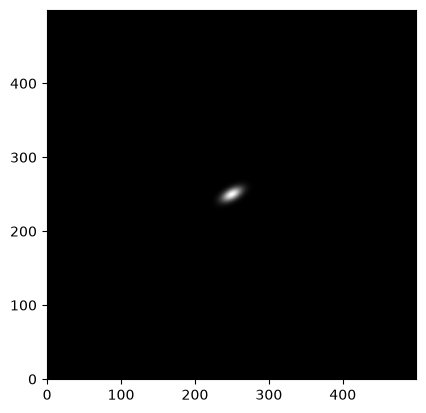

In [2]:
from astropy.modeling.models import Gaussian2D

y, x = np.mgrid[0:500, 0:500]
data = Gaussian2D(1, 250, 250, 10, 5, theta=0.5)(x, y)

plt.imshow(data, origin='lower', cmap='gray')
plt.show

Now we're going to use Cutout2D to er, cut out (crop)

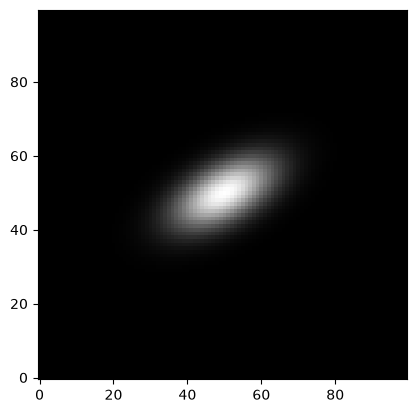

In [3]:
crop_center = (250, 250)
crop_size = units.Quantity((100,100), units.pixel)

# and now the crop!
crop = Cutout2D(data, crop_center, crop_size)
plt.imshow(crop.data, origin='lower', cmap='gray')
plt.show()

### Reading in the FITs data, getting the data we need

We'll iterate through a directory here, read the header from the fits file, then read the image data in and crop it. Finally we'll store it all in a large dict that has this data from all the filed for the next steps.

In [5]:
filenames = glob.glob('data/*.fits')
data_set = {}

for file in filenames:
    # going for the first line
    #file = filenames[0]
    img_header = fits.open(file)
    img_data = fits.getdata(file)

    # we're going to measure the center of the image, 100x100
    crop_center = ((image_data.shape[0] / 2), (image_data.shape[1] / 2))
    crop_size = units.Quantity((100,100), units.pixel)

    # what I want to do
    # open the header and image data
    # create the file object with header info and data:
    #       CCD_TEMP
    #       EXP_TIME
    #       PICTTYPE
    #       img_data.shape <- to verify the proper geometry
    #       CROP(data)
    #       min, max, mean, std_dev

    # Let's create the crop

    img_crop = Cutout2D(img_data, crop_center, crop_size)

    # and write the required header and data into a sample dict

    img_samp = { 'PICTTYPE' : img_header[0].header['PICTTYPE'],
                 'ff_geometry' : img_data.shape,
                 'crop_geometry' : img_crop.shape,
                 'EXPTIME' : img_header[0].header['EXPTIME'],
                 'CCD-TEMP' : img_header[0].header['CCD-TEMP'],
                 'min' : np.min(img_crop.data),
                 'max' : np.max(img_crop.data),
                 'mean' : np.mean(img_crop.data),
                 'std_dev' : np.std(img_crop.data),
                 'data' : img_crop.data
               }

    
    # join it to the main data_set, keyed off file name
    data_set[file.split('/'[1])] = img_sample
    

In [8]:
for x,y in data_set.items():
    print(x, '\ntemp:', (y,['CCD-TEMP']), '\ntype:', (y['PICTTYPE']), '\nEXPTIME:', (y['EXPTIME']), '\nStdDev:', (y['std_dev']))
    plt.imshow(y['data'], origin='lower', cmap='gray')
    plt.colorbar()
    plt.show()

# **FITs Data / Querying the VizieR Catalog**
In order to query the BSC, we will use the [VizieR database](http://vizier.cfa.harvard.edu/) which is a library of published astronomical catalogs. Through VizieR, we can access and query the 5th Revised Ed. of the BSC. In this tutorial, we want stars of [spectral type 'B'](https://en.wikipedia.org/wiki/Stellar_classification#Class_B) with rotation velocity less than 20 km/s.

In [ ]:
from astroquery.vizier import Vizier

# Get the catalog name of the 5th Revised Ed. of the Bright Star Catalog
catalog_list = Vizier.find_catalogs('Bright Star Catalogue, 5th Revised Ed.')
print({k: v.description for k, v in catalog_list.items()})
catalog_key = list(catalog_list.keys())[0]
catalog = Vizier.get_catalogs(catalog_key)
catalog_name = catalog.keys()[0]

# Increase the row limit and query the catalog
Vizier.ROW_LIMIT = 200
result = Vizier.query_constraints(catalog=catalog_name,
                                  SpType='B*',
                                  RotVel='<20')

# Uploading the table does not accept the '-' character so rename column B-V to remove it
bright_star_results.rename_column('B-V', 'B_V')

bright_star_results = result[catalog_name]
bright_star_results

In [ ]:
from astroquery.vizier import Vizier

# 1. Explicitly request the exact columns needed along with standard ones
# This prevents sub-tables from overriding or dropping 'RotVel' and 'SpType'
v_client = Vizier(columns=['HR', 'Name', 'SpType', 'RotVel', 'B-V', 'Vmag'])
v_client.ROW_LIMIT = 10000

# 2. Fetch the catalog data
result = v_client.get_catalogs("V/50")

# 3. Extract the primary data table 
catalog_key = "V/50/catalog"
if catalog_key in result:
    bright_star_results = result[catalog_key]
else:
    bright_star_results = result[list(result.keys())[0]]

# 4. Filter the data safely using list comprehensions 
# Filter 1: Spectral Type starts with 'B' (safely handling blank/missing data)
is_b_star = [
    str(sp).strip().startswith('B') if sp else False 
    for sp in bright_star_results['SpType']
]

# Filter 2: Rotational Velocity is less than 20 km/s (ignoring null/masked records)
is_slow_rotator = [
    not masked and val < 20 
    for val, masked in zip(bright_star_results['RotVel'], bright_star_results['RotVel'].mask)
]

# Merge the masks and index the main table
combined_mask = [b and s for b, s in zip(is_b_star, is_slow_rotator)]
filtered_results = bright_star_results[combined_mask]

# 5. Rename the column safely on your filtered dataset
filtered_results.rename_column('B-V', 'B_V')

# View your final table
filtered_results

**Convert to a Pandas DataFrame**

In [ ]:
df = filtered_results.to_pandas()
print(df.head())

**Hertzsprung-Russell Diagram**

Here is the Python script to generate a beautiful, publication-quality Color-Magnitude Diagram (Hertzsprung-Russell Diagram) and a Rotational Velocity Distribution Histogram side-by-side using `matplotlib`.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Set up a clean, publication-ready style layout
plt.rcParams['font.size'] = 11
plt.rcParams['axes.linewidth'] = 1.2

# Create a side-by-side 1x2 plotting grid
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), tight_layout=True)

# ----------------------------------------------------------------------
# Plot 1: Color-Magnitude Diagram (HR Diagram)
# ----------------------------------------------------------------------
sc = ax1.scatter(
    filtered_results['B_V'], 
    filtered_results['Vmag'], 
    c=filtered_results['RotVel'], 
    cmap='plasma', 
    s=50, 
    edgecolors='black', 
    linewidths=0.7, 
    zorder=3
)

# Astronomical Convention: Magnitudes are brighter towards the top!
ax1.invert_yaxis()

# Labeling axes with units (using raw strings r"" for LaTeX math compatibility)
ax1.set_xlabel(r"Color Index ($B-V$)", fontweight='bold')
ax1.set_ylabel(r"Apparent Visual Magnitude ($V$)", fontweight='bold')
ax1.set_title("Color-Magnitude Diagram (B-Type Stars)", pad=12, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5, zorder=1)

# Fix 1: Changed keyword argument 'ax1' to 'ax'
cbar = fig.colorbar(sc, ax=ax1, pad=0.02)
cbar.set_label(r"Projected Rotational Velocity $v \sin i$ (km/s)", fontweight='bold')

# ----------------------------------------------------------------------
# Plot 2: Rotational Velocity Histogram Distribution
# ----------------------------------------------------------------------
bins = np.arange(0, 22, 2)
counts, edges, bars = ax2.hist(
    filtered_results['RotVel'], 
    bins=bins, 
    color='#1f77b4', 
    edgecolor='black', 
    linewidth=1.0, 
    rwidth=0.9, 
    zorder=3
)

# Annotate counting statistics directly on top of each bin bar
for bar in bars:
    height = bar.get_height()
    if height > 0:
        ax2.annotate(
            f'{int(height)}',
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),  # 3 points vertical offset
            textcoords="offset points",
            ha='center', 
            va='bottom', 
            fontsize=9, 
            fontweight='bold'
        )

ax2.set_xlabel(r"Projected Rotational Velocity $v \sin i$ (km/s)", fontweight='bold')
ax2.set_ylabel("Number of Stars", fontweight='bold')
# Fix 2: Added 'r' prefix to make this a raw string so '\s' isn't evaluated as an escape character
ax2.set_title(r"Rotational Velocity ($v \sin i$) Distribution", pad=12, fontweight='bold')
ax2.set_xticks(np.arange(0, 22, 2))
ax2.grid(True, linestyle='--', alpha=0.5, zorder=1)

# Ensure plot margins have breathing room for text labels
ax2.set_ylim(0, max(counts) * 1.15)

# ----------------------------------------------------------------------
# Save figure down to your disk workspace
# ----------------------------------------------------------------------
output_filename = "slow_b_stars_visualization.png"
plt.savefig(output_filename, dpi=300, bbox_inches='tight')
plt.show()

print(f"Visualization graphic successfully outputted to: {output_filename}")

**An interactive markdown table snippet of the first few stars inside the generated README file**

Here is the complete script to generate your updated README.md. It includes a cleanly formatted Markdown table showcasing the top 5 brightest stars from your dataset, along with a code block demonstrating how to read it [filegen-via-code].

*Add this snippet to the bottom of your Python script*

In [ ]:
# Sort the results by slowest velocity (RotVel) first, then by brightness (Vmag) as a tie-breaker
preview_table = filtered_results.copy()
preview_table.sort(['RotVel', 'Vmag'])

# Build the interactive Markdown table rows dynamically for the top 10 stars
table_rows = []
for row in preview_table[:10]:
    # Replace empty names with clean labels
    name = row['Name'].strip() if row['Name'].strip() else f"HR {row['HR']}"
    table_rows.append(
        f"| {row['HR']} | {name} | {row['SpType']} | {row['RotVel']} km/s | {row['B_V']:.2f} | {row['Vmag']:.2f} |"
    )
markdown_table_content = "\n".join(table_rows)

# Define the full text content of your README.md file (with embedded visualization banner)
readme_content = rf"""# Slow-Rotating B-Type Stars Catalog

This repository contains a filtered subset of the **Bright Star Catalogue, 5th Revised Ed. (VizieR: V/50)**. 

The dataset features slow-rotating B-type stars compiled using `astroquery.vizier` and processed locally with `astropy`.

## Data Visualization
![Slow-Rotating B Stars Data Visualization](slow_b_stars_visualization.png)

## Filtering Criteria
* **Catalog Source:** VizieR V/50 (Bright Star Catalogue)
* **Spectral Type (`SpType`):** Starts with `B` (e.g., B2IV, B7III, B8V)
* **Rotational Velocity (`RotVel`):** Less than 20 km/s (`< 20 km/s`)

## Dataset Summary
* **Total Stars Extracted:** {len(filtered_results)} stars

### Slowest-Rotating Stars Sample Preview (Top 10)

| HR ID | Star Name | Spectral Type | Rotational Velocity | B-V Color | Visual Mag (V) |
|---|---|---|---|---|---|
{markdown_table_content}

## Columns Specification
* `HR`: Harvard Revised Star Number
* `Name`: Bayer or Flamsteed designation (or fallback HR ID)
* `SpType`: MK Spectral Type
* `RotVel`: Projected rotational velocity (\(v \sin i\))
* `B_V`: B-V color index (mag)
* `Vmag`: Apparent visual magnitude (V)

## File Metadata & Warning Notes
When exporting this table to a FITS format, you might notice an `astropy.io.fits.card` warning regarding the keyword name `description`. This is normal behavior. The FITS standard strictly limits header keywords to 8 characters. Because the metadata passed down by the VizieR client uses long descriptive keywords like `description`, Astropy automatically wraps them into standard-compliant `HIERARCH` header blocks. The underlying data matrix remains completely intact.

## Quick Python Usage
To read the generated data files back into your environment:

```python
from astropy.table import Table

# Load the FITS file
table = Table.read('slow_b_stars.fits', format='fits')
print(table)
```
"""

# Write the updated Markdown file to your disk
with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md has been successfully updated with the embedded visualization banner!")

Here is a script snippet you can run to automatically generate a specialized `.gitignore` file optimized for Python, Jupyter notebooks, and astronomical workflows:

In [ ]:
gitignore_content = """# Byte-compiled / optimized / DLL files
__pycache__/
*.py[cod]
*$py.class

# Environments & Virtual Environments
.venv/
venv/
env/
astro_env/
ENV/

# Jupyter Notebook checkpoints & runtime logs
.ipynb_checkpoints/
.pytest_cache/
.history/
*.log

# Operating System specific files
.DS_Store
Thumbs.db

# Optional: Large data or local configuration formats
# (Uncomment the line below if you don't want to track the heavy raw/unfiltered files)
# *.fits
"""

# Write the file down to your workspace root directory
with open(".gitignore", "w", encoding="utf-8") as file:
    file.write(gitignore_content)

print(".gitignore has been generated and saved successfully!")

# **FITs Data / Imaging Quasars**

In this notebook, we will image quasars, grabbing our targets from the SDSS SPIDERS catalog, and collecting the images from the [Canadian Astronomical Data Centre](http://www.cadc-ccda.hia-iha.nrc-cnrc.gc.ca ). We will use the `astropy`, `astroquery`, and `matplotlib` packages in order to query, refine, and visualize the data. The goal is to show some of the basic functionalities of the CADC astroquery by going through a simple end-to-end example.

---

## 1. Querying

### 1.1 Finding suitable quasars
For this tutorial, we want to look at quasars within a particular redshift range. We will use the SDSS SPIDERS catalog to look at quasars and their properties. Looking through the [SDSS schema browser](https://skyserver.sdss.org/dr14/en/help/browser/browser.aspx#&&history=shortdescr+Tables+U), the `spiders_quasar` table suits our needs the most. We can get more information about the table, as well as descriptions of its columns, in the [table schema](https://skyserver.sdss.org/dr14/en/help/browser/browser.aspx#&&history=description+spiders_quasar+U). We will grab the `name`, `DR14_PLUG_RA`, `DR14_PLUG_DEC`, `MJD`, `redshift`, `CLASS_BEST`, `CONF_BEST` and `DR14_ZWARNING` columns where `redshift` is greater than 1.3 but less than 1.5. Additionally, we want `CLASS_BEST`, the source classification, to be of type 'QSO' and `DR14_ZWARNING`, the warning flag, to be '0' or off.

We can actually query and collect the quasar catalog data in one step using the SkyServer API. There is a SQL search service which allows us to pass in an SQL query and it returns the results in the specified format. Check the [API docs](https://skyserver.sdss.org/dr14/en/help/docs/api.aspx#search) for more information about the service.

In [ ]:
from urllib.parse import urlencode

from astropy.table import Table

# Define the query
query = """SELECT name, DR14_PLUG_RA AS RA, DR14_PLUG_DEC AS DEC, MJD, redshift, 
CLASS_BEST, CONF_BEST FROM spiders_quasar 
WHERE ( redshift > {redshift_lower} AND redshift < {redshift_upper} 
AND CLASS_BEST='QSO' AND DR14_ZWARNING=0 )""".format(redshift_lower=1.3,
                                                     redshift_upper=1.5)

# Build the request
base_url = 'http://skyserver.sdss.org/dr14/SkyServerWS/SearchTools/SqlSearch'
parameters = {'cmd': query, 'format': 'fits'}
url_params = urlencode(parameters)
data_url = '{}?{}'.format(base_url, url_params)

# Grab the data from the url and convert to a pandas dataframe
qso_table = Table.read(data_url, format='fits')
qso_data = qso_table.to_pandas()

# Convert byte strings to regular strings
qso_data["CLASS_BEST"] = qso_data["CLASS_BEST"].str.decode("utf-8")
qso_data["name"] = qso_data["name"].str.decode("utf-8")

print('Number of results: {}'.format(len(qso_data)))
qso_data.head()

We have a list of suitable quasars! Now, in order to query the CADC data, we are going to extract the coordinates and search for all `CFHTMEGAPIPE` data collections in those coordinates.

### 1.2 Querying with the `query_region` function
The simplest way to query data by target position is to use the `query_region` function. It takes a set of coordinates (radius and collection source are optional) and returns all the results that intersect with the coordinates. After querying, we can further refine the results and remove unwanted rows using boolean masks on the data. In order to do this refinement of the data, we need to see which columns are in the results and what data type they are. But first, let's do the query.

In [ ]:
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.table import vstack
from astroquery.cadc import Cadc

# Instantiate cadc module
cadc = Cadc()

# Get target name, redshift, ra, and dec
name_list = qso_data['name'].values
redshift_list = qso_data['redshift'].values
ra_list = qso_data['RA'].values
dec_list = qso_data['DEC'].values

# Build a list of skycoords from target ra and dec
coords_list = [
    SkyCoord(ra, dec, frame='icrs', unit='deg')
    for ra, dec in zip(ra_list, dec_list)
]

# Iterate through target coords and run query on each
results_list = []
for name, coords, redshift in zip(name_list, coords_list, redshift_list):
    results = cadc.query_region(coords,
                                radius=0.01 * u.deg,
                                collection='CFHTMEGAPIPE')
    if len(results):
        # We add target coordinates as columns to results to make cutout process easier
        results['qso_name'] = name
        results['qso_ra'] = coords.ra
        results['qso_dec'] = coords.dec
        results['qso_redshift'] = redshift
        results_list.append(results)

# Then vertically combine all the results into one table
results = vstack(results_list)

print('Number of results pre-reduction: {}'.format(len(results)))

Now that we have results in the coordinates we want from the CFHT MegaPipe data, we should further reduce the data. We can take a look at the columns in the results by accessing `results.colnames`, and furthermore, we can get a description of each column using the `results.info()` function. For this tutorial, we want to image results that have the ['i' filter ](https://www.cadc-ccda.hia-iha.nrc-cnrc.gc.ca/en/megapipe/docs/filt.html), so the `energy_bandpssName` must start with `i`. We also want `dataProductType` of type `image`. Another thing to mention is that some quasars appear twice in the dataset (since they have been identified by both the 2RXS and XMMSL1 surveys), so if two quasars in the results are in nearly the same spot, we will only keep one of them. Once we reduce the results, we will display a subset of the columns (since there are so many!).

In [ ]:
from astropy.table import unique

# Construct the reduction mask
results_mask = ([energy_bandpass_name.startswith('i.') for energy_bandpass_name in
                 results['energy_bandpassName']]) &\
    (results['dataProductType'] == 'image')

# Apply the reduction mask to the results
masked_results = results[results_mask]

# Unique on quasar target name
masked_results = unique(masked_results, keys='qso_name')

# Remove duplicate quasars that appear in both 2RXS and XMMSL1 surveys
# Check if the difference between the ra and dec is within a threshold
deg_thres = 0.0001
masked_results.sort('qso_ra')
idx_to_remove = []
for idx, result in enumerate(masked_results[1:]):
    if ((abs(result['qso_ra'] - masked_results[idx]['qso_ra']) < deg_thres) and
        (abs(result['qso_dec'] - masked_results[idx]['qso_dec']) < deg_thres)):
        idx_to_remove.append(idx)
masked_results.remove_rows(idx_to_remove)

# Sort by redshift
masked_results.sort('qso_redshift')

columns_subset = [
    'qso_name', 'qso_ra', 'qso_dec', 'qso_redshift', 'productID', 'collection',
    'energy_bandpassName', 'dataProductType'
]

print('Number of results post-reduction: {}'.format(len(masked_results)))
masked_results[columns_subset][0:5]

## 2. Fetching Data
Now let's get access to the results, download them, and display them. We will use the `get_image_list` function to get cutout urls of the results. Since that function takes a table, we will stack the results and comparisons table. We also want to calculate the time difference between the time the image was captured and the supernova maximum date and append it to the results table.

In [ ]:
import re
import warnings

from astropy.io import fits
from astropy.wcs import WCS

# Supress fits processing warnings
warnings.simplefilter('ignore')

data_list = []

# Grab cutout urls of the table of results around the supernova position
for idx, result in enumerate(masked_results):
    ra = result['qso_ra']
    dec = result['qso_dec']
    cutout_url = cadc.get_image_list(
        masked_results[idx:idx + 1], SkyCoord(ra,
                                              dec,
                                              frame='icrs',
                                              unit='deg'), 0.01*u.deg)[0]

    # Access the url and fetch the data
    try:
        with fits.open(cutout_url) as hdulist:
            wcs = WCS(hdulist[0].header)
            image_data = hdulist[0].data
            data_list.append({
                'image_data': image_data,
                'wcs': wcs,
                'qso_name': result['qso_name'],
                'qso_ra': ra,
                'qso_dec': dec,
                'qso_redshift': result['qso_redshift']
            })
    except:
        print('Error: Problem with {}'.format(cutout_url))
        continue

print("Finished processing images.")

## 3. Plotting Results

Now that we have the image data and the coordinate data of all our cutouts, we can begin to plot the data! First we will grab the image data for all the results and check if it is valid. We will remove the images that have more than 5% blank pixels, as well as images with aspect ratio less than 0.8 and greater than 1.2. Then we will display the list of quasars, as well as their corresponding redshift values.

In [ ]:
import numpy as np


def clean_image_list(data_list):
    """Cleans out the incomplete and ill-formatted images and returns the datalist"""
    def exists(data):
        return data['image_data'] is not None

    def percent_nonzero_above_x(data, x=0.95):
        image_data = data['image_data']
        return np.count_nonzero(image_data) / image_data.size > x

    def square_image(data, ratio_bounds=(0.8, 1.2)):
        x, y = data['image_data'].shape
        return (x / y > ratio_bounds[0] and x / y < ratio_bounds[1])

    # Clean the images on number of nonzero pixels and aspect ratio
    return list(
        filter(
            lambda data: exists(data) and percent_nonzero_above_x(data) and
            square_image(data), data_list))


cleaned_data_list = clean_image_list(data_list)
print('Number of images pre-clean: {}'.format(len(data_list)))
print('Final number of cleaned images: {}'.format(len(cleaned_data_list)))

In [ ]:
%matplotlib inline
import math

import matplotlib.pyplot as plt
from astropy.visualization import ImageNormalize, LinearStretch, ZScaleInterval

np.seterr(divide='ignore', invalid='ignore')


def plot_image_list(data_list, geo=None):
    """ Plot the quasar image list"""

    # Build a layout if none is passed in
    if geo is None:
        geo = (len(data_list), 1)  # ncols, nrows

    # Dynamically create figsize based on layout
    fig = plt.figure(figsize=(geo[0] * 3, geo[1] * 3))
    fig.suptitle('Images of Quasars', fontsize=14, fontweight='bold', y=0.94)

    for idx, data in enumerate(data_list):
        ax = plt.subplot(geo[1], geo[0], idx + 1, projection=data['wcs'])

        # Draw yellow circle around quasar position
        ax.scatter(data['qso_ra'],
                   data['qso_dec'],
                   transform=ax.get_transform('icrs'),
                   s=800,
                   edgecolor='yellow',
                   facecolor='none')
        image_data_norm = ImageNormalize(data['image_data'],
                                         interval=ZScaleInterval(),
                                         stretch=LinearStretch())
        ax.imshow(data['image_data'], norm=image_data_norm, cmap='gray')
        ax.set_title(data['qso_name'])

        # Print redshift value
        ax.text(20,
                20,
                'z={:.3}'.format(data['qso_redshift']),
                fontsize=12,
                color='white',
                bbox={
                    'facecolor': 'blue',
                    'alpha': 0.5,
                    'pad': 3
                })
        ax.coords.grid(color='white', ls='solid')
        ra, dec = ax.coords['ra'], ax.coords['dec']
        ra.set_ticklabel_visible(False)
        dec.set_ticklabel_visible(False)
        ra.set_axislabel('')
        dec.set_axislabel('')


ncols = 5
nrows = math.ceil(len(cleaned_data_list) / ncols)
plot_image_list(cleaned_data_list, geo=(ncols, nrows))

Here is the final list of quasars. Luckily, we have caught one of the most well known quasars in our results! The [Twin Quasar](https://en.wikipedia.org/wiki/Twin_Quasar), with redshift `z=1.42`, labeled `2RXS J100121.5+555351` and `XMMSL1 J100119.9+555357` is actually one quasar that appears as two because of gravitational lensing. It is one of the first identified gravitationally lensed objects.

## References

Coffey,  D., Salvato, M., Merloni, A., Boller, Th., Nandra, K., Dwelly, T., Comparat, J., Schulze, A., Del Moro, A., and Schneider, D. P.,  “SDSS-IV/SPIDERS:  A catalogue of X-ray selected AGN properties - Spectral properties and black hole mass estimates for SPIDERS SDSS DR14 type 1 AGN,” _A&A_, vol. 625, p. A123, 2019.
  
Gwyn, S. D. J.,  “MegaPipe:  The MegaCam Image Stacking Pipeline at the Canadian Astronomical Data Centre,” _PASP_, vol. 120, p. 212, 2008.